In [1]:


%pip install -q ucimlrepo pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
data =pd.read_csv("online_shoppers_intention.csv")
X=data.drop(columns=['Revenue'])
y=data['Revenue']

In [4]:
display(X.head)

<bound method NDFrame.head of        Administrative  Administrative_Duration  Informational  \
0                   0                      0.0              0   
1                   0                      0.0              0   
2                   0                      0.0              0   
3                   0                      0.0              0   
4                   0                      0.0              0   
...               ...                      ...            ...   
12325               3                    145.0              0   
12326               0                      0.0              0   
12327               0                      0.0              0   
12328               4                     75.0              0   
12329               0                      0.0              0   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                         0.0               1                 0.000000   
1                         0.0            

In [5]:
print("Number of sessions:", X.shape[0])
print("Number of input features:", X.shape[1])
print("\nFeature names:")
print(X.columns.tolist())

Number of sessions: 12330
Number of input features: 17

Feature names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


Revenue
False    10422
True      1908
Name: count, dtype: int64


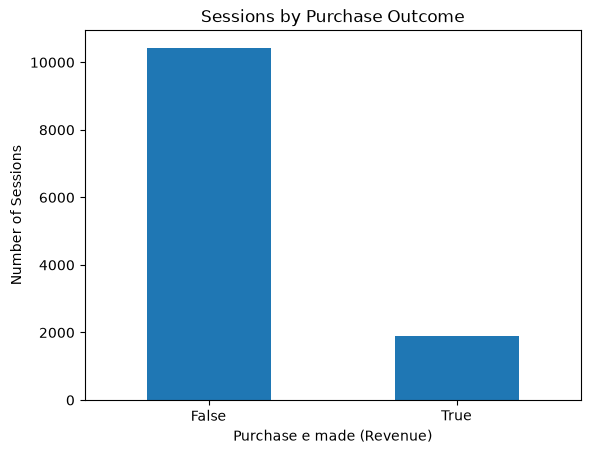

In [7]:
print(y.value_counts())
y.value_counts().plot(kind="bar")
plt.title("Sessions by Purchase Outcome")
plt.xlabel("Purchase e made (Revenue)")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.show()

In [8]:
print("Missing values:")
display(X.isnull().sum())
print("\nData types:")
display(X.dtypes)
print("\nTarget values:")
print(y.value_counts(dropna=False))

Missing values:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
dtype: int64


Data types:


Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
dtype: object


Target values:
Revenue
False    10422
True      1908
Name: count, dtype: int64


In [9]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Month', 'VisitorType']
Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']


C:\Users\Admin\AppData\Local\Temp\ipykernel_25144\3337680641.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
C:\Users\Admin\AppData\Local\Temp\ipykernel_25144\3337680641.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.py

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training sessions:", len(X_train))
print("Testing sessions:", len(X_test))

Training sessions: 9864
Testing sessions: 2466


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

ann_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("neural_network", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

print("ANN pipeline created.")

ANN pipeline created.


In [12]:
ann_model.fit(X_train, y_train)
print("Training completed!")

Training completed!


In [13]:
y_pred = ann_model.predict(X_test)
y_probability = ann_model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Actual Revenue": y_test.values,
    "Predicted Revenue": y_pred
})
display(results.head(10))

,Actual Revenue,Predicted Revenue
0,False,False
1,False,False
2,True,True
3,False,False
4,False,False
5,False,False
6,True,False
7,False,False
8,False,False
9,False,False


In [14]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=True, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=True, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=True, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC-AUC:   {roc_auc:.3f}")

Accuracy:  0.888
Precision: 0.668
Recall:    0.558
F1-score:  0.608
ROC-AUC:   0.901


In [15]:
print(classification_report(
    y_test, y_pred,
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

              precision    recall  f1-score   support

 No purchase       0.92      0.95      0.94      2084
    Purchase       0.67      0.56      0.61       382

    accuracy                           0.89      2466
   macro avg       0.79      0.75      0.77      2466
weighted avg       0.88      0.89      0.88      2466



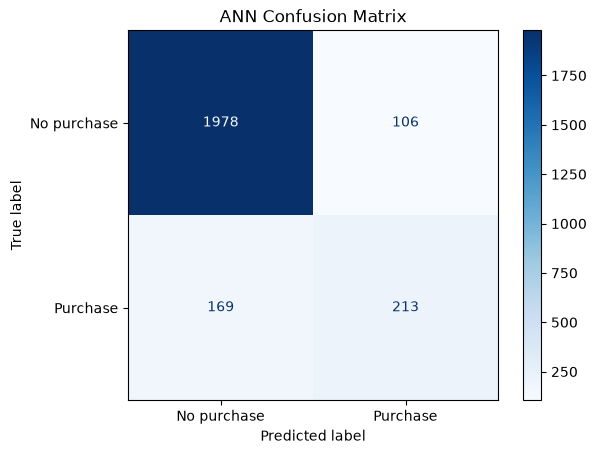

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No purchase", "Purchase"],
    cmap="Blues"
)
plt.title("ANN Confusion Matrix")
plt.show()

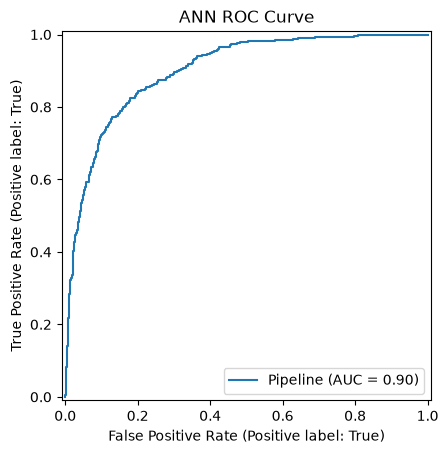

In [17]:
RocCurveDisplay.from_estimator(ann_model, X_test, y_test)
plt.title("ANN ROC Curve")
plt.show()

In [18]:
sample_session = X_test.iloc[[0]]
sample_prediction = ann_model.predict(sample_session)[0]
sample_probability = ann_model.predict_proba(sample_session)[0, 1]

print("Predicted outcome:", "Purchase" if sample_prediction else "No purchase")
print(f"Estimated purchase probability: {sample_probability:.1%}")
display(sample_session)

Predicted outcome: No purchase
Estimated purchase probability: 0.3%


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
4722,1,4.0,0,0.0,13,161.166667,0.024615,0.061538,0.0,0.6,May,2,5,9,5,Returning_Visitor,False


In [19]:
print("Your model's test results:")
print(f"Accuracy: {accuracy:.3f}")
print(f"Purchase precision: {precision:.3f}")
print(f"Purchase recall: {recall:.3f}")
print(f"Purchase F1-score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

Your model's test results:
Accuracy: 0.888
Purchase precision: 0.668
Purchase recall: 0.558
Purchase F1-score: 0.608
ROC-AUC: 0.901


Let's understand the entire practical from the beginning. I'll explain **what we are building, why each step is necessary, and what every important line of code does**.

The aim is not just to run the notebook. By the end, you should be able to explain how the data enters the neural network, how the network learns, and how we know whether its predictions are good.

# **1. Understanding the project**

[Jak śledzić ruch i stosować analitykę w sklepie internetowym? Sprawdź teraz! - widoczni](https://images.openai.com/static-rsc-4/3U1cz0MmP9LPNah-cReu4-yPP8cBWqolkOnFRNHeAt2YoQp0vRMnSPtvKCBbYttjdx7eeimSJUfsd5Qzg5TwbhxD5Cmx-4H0TV040JGqr5mJwZ2tlEQyuDv--QgRetHz9T7_dw860w57YqDlqXL9FE-HSDl_lDqoRAKh6ON6Sfk?purpose=inline)

[widoczni.com](https://widoczni.com/blog/jak-sledzic-ruch-i-stosowac-analityke-w-sklepie/?utm_source=chatgpt.com)

Imagine you own an online shop.

Thousands of people visit your website every day. Some visitors buy products, while others leave without buying anything.

You want to build an Artificial Neural Network (ANN) that can learn from previous shopping sessions and predict whether a new session is likely to result in a purchase.

**Our prediction problem:**

- Input: Information about a shopping session.
- Neural network: Learns patterns from previous sessions.
- Output: Purchase or no purchase.

For example:

| Input information   | Example           |
| ------------------- | ----------------- |
| Pages visited       | 5                 |
| Time spent browsing | 120 seconds       |
| Visitor type        | Returning visitor |
| Month               | November          |
| Weekend             | Yes               |
| Purchase result     | True              |

The dataset has 12,330 shopping sessions. Its target column is called `Revenue`.

- `True` means a purchase was recorded.
- `False` means no purchase was recorded.

One important distinction: a session without a purchase is not necessarily a confirmed cart abandonment. Our model predicts purchase outcomes, not verified cart abandonment.

# **2. Step 1 — Installing the libraries**

Our first code cell is:

```
%pip install -q ucimlrepo pandas numpy matplotlib scikit-learn
```

Before writing a program, we need tools that help Python perform different tasks.

Think of libraries as toolboxes. Instead of writing every operation ourselves, we use existing tools.

Let's understand each library.

| Library        | Purpose                                        |
| -------------- | ---------------------------------------------- |
| `ucimlrepo`    | Downloads the dataset from UCI                 |
| `pandas`       | Works with tables and datasets                 |
| `numpy`        | Performs numerical calculations                |
| `matplotlib`   | Creates charts and graphs                      |
| `scikit-learn` | Prepares data, trains the ANN and evaluates it |

**What does&#x20;**`%pip install`**&#x20;mean?**

It tells Jupyter to install the libraries into the Python environment used by the notebook.

The `-q` means quiet mode. It reduces installation messages.

Note: `%pip` is a Jupyter notebook command, not ordinary Python syntax for a `.py` file.

# **3. Step 2 — Importing the libraries**

Our next code is:

```
import pandas as pdimport numpy as npimport matplotlib.pyplot as plt
```

Let's break it down.

**First line:**

```
import pandas as pd
```

We import the pandas library and give it the short name `pd`.

Instead of writing:

```
pandas.head()
```

we can use:

```
pd.head()
```

In this project, pandas helps us inspect and organize the shopping dataset.

**Second line:**

```
import numpy as np
```

NumPy helps us perform numerical operations.

We give it the short name `np`.

**Third line:**

```
import matplotlib.pyplot as plt
```

Matplotlib helps us create visualizations.

For example, we use it to display how many shopping sessions resulted in purchases and how many did not.

Now look at the next imports:

```
from ucimlrepo import fetch_ucirepo
```

This imports a function called `fetch_ucirepo`.

We use it to retrieve the dataset.

The remaining imports come from scikit-learn:

```
from sklearn.model_selection import train_test_splitfrom sklearn.compose import ColumnTransformerfrom sklearn.preprocessing import OneHotEncoder, StandardScalerfrom sklearn.pipeline import Pipelinefrom sklearn.neural_network import MLPClassifier
```

Here is what they do:

| Function or class   | What it does                                               |
| ------------------- | ---------------------------------------------------------- |
| `train_test_split`  | Divides the dataset into training and testing data         |
| `ColumnTransformer` | Applies different preparation methods to different columns |
| `OneHotEncoder`     | Converts categories into numerical columns                 |
| `StandardScaler`    | Scales numerical values                                    |
| `Pipeline`          | Connects data preparation and model training               |
| `MLPClassifier`     | Creates our neural network                                 |

Finally:

```
from sklearn.metrics import (    accuracy_score, precision_score, recall_score, f1_score,    classification_report, ConfusionMatrixDisplay,    RocCurveDisplay, roc_auc_score)
```

These functions help us measure how well our model performs.

# **4. Step 3 — Downloading the dataset**

Our code:

```
online_shoppers = fetch_ucirepo(id=468)X = online_shoppers.data.features.copy()y = online_shoppers.data.targets.squeeze().copy()
```

This is one of the most important steps.

We are obtaining the actual dataset from the UCI Machine Learning Repository.

The dataset is called the **Online Shoppers Purchasing Intention Dataset**.

You can find it here:

[Open the official UCI dataset](https://archive.ics.uci.edu/dataset/468/online?utm_source=chatgpt.com).

Let's understand each line.

**Line 1:**

```
online_shoppers = fetch_ucirepo(id=468)
```

- `fetch_ucirepo()` downloads a dataset.
- `id=468` tells it which dataset we want.
- `online_shoppers` stores the downloaded dataset.

We can think of this variable as a container holding the dataset information.

**Line 2:**

```
X = online_shoppers.data.features.copy()
```

This extracts the input features.

What are features?

Features are the pieces of information that the neural network uses to make a prediction.

Examples include:

- Number of administrative pages visited.
- Time spent on different pages.
- Bounce rate.
- Exit rate.
- Month.
- Visitor type.
- Weekend.

We call these inputs `X`.

**Line 3:**

```
y = online_shoppers.data.targets.squeeze().copy()
```

This extracts the target.

The target is the answer we want our neural network to learn to predict.

In our case:

```
Revenue = True
Revenue = False
```

We call the target `y`.

**Remember this distinction**

# **X**

**Input features**

Information about the shopping session.

# **y**

**Target**

Whether a purchase happened.

The neural network learns the relationship between X and y.

**What does&#x20;**`.copy()`**&#x20;do?**

It creates a separate copy of the data so that changes we make to our working data do not unintentionally modify the original dataset object.

**What does&#x20;**`.squeeze()`**&#x20;do?**

It removes unnecessary dimensions from the target data.

For example, it can turn a one-column table into a simpler one-dimensional series.

# **5. Step 4 — Exploring the dataset**

Now that we have downloaded the data, we need to understand it before training anything.

Our first code:

```
display(X.head())
```

`head()` displays the first five rows by default.

Why do we do this?

Because we need to see what our data looks like.

For example, the output may look conceptually like this:

| Administrative | Informational | ProductRelated | Month |
| -------------- | ------------- | -------------- | ----- |
| 0              | 0             | 1              | Feb   |
| 2              | 1             | 5              | Mar   |
| 1              | 0             | 10             | May   |
| 3              | 2             | 7              | Nov   |
| 0              | 0             | 2              | Dec   |

These are example values to illustrate the columns, not actual results from your notebook.

Next:

```
print("Number of sessions:", X.shape[0])
```

`shape` tells us the dimensions of a dataset.

For example:

```
X.shape
```

might return:

```
(12330, 17)
```

This means:

- 12,330 rows.
- 17 input columns.

The first number is the number of rows. The second is the number of columns.

Next:

```
print("Number of input features:", X.shape[1])
```

This extracts only the number of columns.

Finally:

```
print(X.columns.tolist())
```

This displays the names of the input columns.

It helps us understand what information the model will receive.

# **6. Step 5 — Understanding the target column**

Our code:

```
print(y.value_counts())
```

This counts how many times each target value appears.

For example, the dataset contains:

| Revenue | Number of sessions |
| ------- | ------------------ |
| False   | 10,422             |
| True    | 1,908              |

This tells us that more sessions did not result in purchases.

We also create a bar chart:

```
y.value_counts().plot(kind="bar")plt.title("Sessions by Purchase Outcome")plt.xlabel("Purchase made (Revenue)")plt.ylabel("Number of sessions")plt.xticks(rotation=0)plt.show()
```

Let's understand the commands.

- `.plot(kind="bar")` creates a bar chart.
- `plt.title()` gives the chart a title.
- `plt.xlabel()` labels the horizontal axis.
- `plt.ylabel()` labels the vertical axis.
- `plt.xticks(rotation=0)` keeps the category labels horizontal.
- `plt.show()` displays the chart.

[Predict if a Customer will Purchase on a website or not? | by Jay Narayan | Analytics Vidhya | Medium](https://images.openai.com/static-rsc-4/1UYYoZ6Natp8NP30mL6fb1EK1R4sz0d24hJbjXVcV--lx5bzuD1ZOMnBB5kJAiFVCrVz-afFRa1zIJpPFn6qjxD_DuYWq0ViPWc8jaZot65xz8cBP3MdA-UkWoHFTHAgwJyqNoRvpoukIjm2HoyGJIOzi5F2V2sdeXAPkLAck9s?purpose=inline)

[medium.com](https://medium.com/analytics-vidhya/predict-if-a-customer-will-purchase-on-a-website-or-not-b785e7f5697f?utm_source=chatgpt.com)

**Why is this important?**

Because our dataset is imbalanced.

There are many more `False` values than `True` values.

Imagine a model that predicts `False` for every single session. It could still achieve approximately 84.5% accuracy, despite never identifying a purchase.

That is why we need more than accuracy to evaluate our neural network.

# **7. Step 6 — Checking data quality**

Our code:

```
print("Missing values:")display(X.isnull().sum())
```

Let's break it down.

`isnull()` checks whether values are missing.

`.sum()` counts how many missing values exist in each column.

For example:

| Column      | Missing values |
| ----------- | -------------- |
| Month       | 0              |
| VisitorType | 0              |
| Weekend     | 0              |
| BounceRates | 0              |

This is an illustrative table.

Why do we check this?

Because missing information can cause problems when training a model. We need to know whether values are absent and whether they require treatment.

Next:

```
display(X.dtypes)
```

`dtypes` tells us the data type of each column.

For example:

- `int64` means an integer number.
- `float64` means a decimal number.
- `object` often represents text or categories.
- `bool` represents True or False.

Then:

```
print(y.value_counts(dropna=False))
```

This counts the target values, including missing values if any exist.

# **8. Step 7 — Identifying numerical and categorical features**

This is an important preparation step.

Our code:

```
categorical_features = X.select_dtypes(    include=["object", "category"]).columns.tolist()
```

What does it do?

1. `select_dtypes()` selects columns based on their data types.
2. `include=["object", "category"]` selects text and category columns.
3. `.columns` retrieves their names.
4. `.tolist()` turns the names into a Python list.

The result is stored in:

```
categorical_features
```

Next:

```
numerical_features = X.select_dtypes(    exclude=["object", "category"]).columns.tolist()
```

This selects the remaining columns.

We store them in:

```
numerical_features
```

Why do we separate them?

Because numbers and categories need different preparation.

For example:

- `Month = November` is a category.
- `Administrative_Duration = 120.5` is a numerical value.

A neural network needs numerical inputs, so we must convert categories into numbers appropriately.

# **9. Step 8 — Splitting the dataset**

Our code:

```
X_train, X_test, y_train, y_test = train_test_split(    X, y, test_size=0.20, random_state=42, stratify=y)
```

This is one of the most important ideas in machine learning.

We divide our dataset into two parts.

**Our data split**

**80% Training**

**20% Testing**

- Training: teaches the model.
- Testing: checks whether the model learned patterns that work on unseen data.

Let's understand the arguments.

`X, y`

These are the features and target we want to split.

`test_size=0.20`

This means 20% of the data is reserved for testing.

The remaining 80% is used for training.

`random_state=42`

This makes the random split reproducible.

If you run the notebook again with the same data and settings, you should get the same split.

The number 42 is simply a chosen seed; it has no special mathematical meaning here.

`stratify=y`

This helps preserve the proportions of purchases and non-purchases in both groups.

For example, if about 15.5% of the original sessions resulted in purchases, we want roughly the same percentage in the training and testing sets.

Finally, we get four variables:

| Variable  | Meaning                  |
| --------- | ------------------------ |
| `X_train` | Training input features  |
| `X_test`  | Testing input features   |
| `y_train` | Correct training answers |
| `y_test`  | Correct testing answers  |

# **10. Step 9 — Preparing the data**

Now we reach an important part: making the data suitable for the neural network.

Our code:

```
preprocessor = ColumnTransformer(    transformers=[        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),        ("numerical", StandardScaler(), numerical_features)    ])
```

Let's understand what happens.

## **A. OneHotEncoder**

Imagine we have a column called `Month`.

It contains:

```
January
February
March
```

A neural network cannot directly perform mathematical calculations with these words.

One-hot encoding changes categories into separate numerical columns.

For example:

| Month    | January | February | March |
| -------- | ------- | -------- | ----- |
| January  | 1       | 0        | 0     |
| February | 0       | 1        | 0     |
| March    | 0       | 0        | 1     |

The network can now work with these numbers.

Our code:

```
OneHotEncoder(handle_unknown="ignore")
```

`handle_unknown="ignore"` tells the encoder what to do if it encounters a category it did not see during training.

Instead of crashing, it ignores that unknown category in the encoded representation.

## **B. StandardScaler**

Now imagine we have two numerical columns:

- Number of pages visited: 5
- Time spent browsing: 500 seconds

These values have different scales.

StandardScaler helps bring numerical features onto comparable scales.

It uses the formula:

\\[ z=\frac{x-\mu}{\sigma} \\]

Where:

- \\(x\\) = original value.
- \\(\mu\\) = mean (average).
- \\(\sigma\\) = standard deviation.
- \\(z\\) = scaled value.

This helps the neural network learn without being unnecessarily affected by differences in measurement scales.

## **C. ColumnTransformer**

Why use `ColumnTransformer`?

Because we want to apply:

- OneHotEncoder to categorical columns.
- StandardScaler to numerical columns.

It combines the results into one prepared dataset.

# **11. Step 10 — Creating the neural network**

Now we create the actual ANN.

Our code:

```
ann_model = Pipeline(steps=[    ("preprocessing", preprocessor),    ("neural_network", MLPClassifier(        hidden_layer_sizes=(16, 8),        activation="relu",        solver="adam",        max_iter=300,        early_stopping=True,        random_state=42    ))])
```

Let's first understand the overall structure.

[It's a No Brainer: An Introduction to Neural Netwo... - Alteryx Community](https://images.openai.com/static-rsc-4/7VtGyY-c0nhalrmRfV5pjP7hxPzLdF_oErBfdjimx9656ANHcJotq-YMXD4huKdor6pjiV-wCmJ_OeVS-s0MV9-dD6gBMTrKXqcWAj1peau43e3_03uBO6mujoZs1aGKm0h2LOTW07DahsnQTh-vT1D4TopmKW1KDYIm4dQsuIk?purpose=inline)

[community.alteryx.com](https://community.alteryx.com/t5/Data-Science/It-s-a-No-Brainer-An-Introduction-to-Neural-Networks/ba-p/300479?utm_source=chatgpt.com)

A neural network has:

1. Input layer.
2. Hidden layer or layers.
3. Output layer.

In our project:

**Input layer**

Receives the prepared shopping-session features.

**Hidden layers**

Learn patterns and relationships between the input features and purchase outcomes.

**Output layer**

Produces the prediction: purchase or no purchase.

Now let's examine the code.

### `Pipeline`

```
Pipeline(steps=[...])
```

A pipeline connects multiple operations together.

In our case:

1. Prepare the data.
2. Train the neural network.

This means we don't have to manually prepare the training data and then remember to prepare the test data in exactly the same way.

### `MLPClassifier`

```
MLPClassifier(...)
```

MLP means **Multilayer Perceptron**.

It is a type of artificial neural network used for classification.

Classification means predicting a category, such as:

- Purchase.
- No purchase.

### `hidden_layer_sizes=(16, 8)`

This is very important.

It means our network has two hidden layers.

- First hidden layer: 16 neurons.
- Second hidden layer: 8 neurons.

**Our hidden-layer arrangement**

**Input**

# **17+**

Prepared features

**Hidden 1**

# **16**

Neurons

**Hidden 2**

# **8**

Neurons

**Output**

# **2**

Classes

The number of prepared input columns can be greater than 17 because one-hot encoding expands categorical columns. The two output classes are purchase and no purchase.

### `activation="relu"`

ReLU stands for Rectified Linear Unit.

It is an activation function that helps the network learn non-linear relationships.

Its formula is:

\\[ f(x)=\max(0,x) \\]

For example:

- If \\(x=5\\), output is 5.
- If \\(x=-3\\), output is 0.

### `solver="adam"`

Adam is the optimization algorithm used to update the network's weights during training.

Remember the lecture's explanation of weights and learning?

The network adjusts its weights to reduce its prediction errors.

Adam helps perform these adjustments.

### `max_iter=300`

This sets the maximum number of training iterations.

It does not guarantee that the model will use all 300. Other stopping conditions may stop training earlier.

### `early_stopping=True`

This allows training to stop early if performance on an internal validation portion of the training data stops improving.

It helps avoid unnecessary training and can help reduce overfitting.

### `random_state=42`

This makes the model's random initialization and related random operations reproducible.

# **12. Step 11 — Training the neural network**

Our code:

```
ann_model.fit(X_train, y_train)print("Training completed!")
```

This is where the actual learning begins.

The `.fit()` method gives the model:

- `X_train`: shopping-session information.
- `y_train`: the correct purchase outcomes.

The model uses the training examples to learn relationships between inputs and outputs.

Let's connect this to your lecture.

In the lecture, you learned about:

- Weights.
- Bias.
- Weighted sums.
- Activation functions.
- Prediction errors.
- Loss.
- Gradient descent.
- Updating weights.

Those ideas explain how a neural network learns.

Our `MLPClassifier` performs these calculations internally. We don't manually write every weight update in this practical because the library handles them.

**Important:** We have not removed the mathematics from the project. We are using a library to perform the training process automatically.

# **13. Step 12 — Making predictions**

After training, we test the model.

Our code:

```
y_pred = ann_model.predict(X_test)
```

This asks the trained neural network to predict the outcomes of the testing sessions.

The predictions will be categories:

```
True
False
True
False
```

Next:

```
y_probability = ann_model.predict_proba(X_test)[:, 1]
```

This gives the predicted probability of the positive class.

In this dataset, the positive class is `True`, meaning a purchase.

For example, a prediction might be:

```
No purchase probability: 0.20
Purchase probability:    0.80
```

The model predicts a purchase because its purchase probability is higher.

The `[:, 1]` selects the probability column for the second class. In this dataset, scikit-learn's class ordering places `True` after `False`.

Finally:

```
results = pd.DataFrame({    "Actual Revenue": y_test.values,    "Predicted Revenue": y_pred})
```

This creates a table comparing:

- The actual answer.
- The model's prediction.

For example:

| Actual Revenue | Predicted Revenue |
| -------------- | ----------------- |
| True           | True              |
| False          | False             |
| True           | False             |
| False          | True              |

This allows us to see where the model made correct and incorrect predictions.

# **14. Step 13 — Evaluating the model**

This is where we determine whether our ANN is performing well.

We use five main evaluation metrics.

## **A. Accuracy**

```
accuracy = accuracy_score(y_test, y_pred)
```

Accuracy measures the proportion of all predictions that are correct.

\\[ Accuracy=\frac{\text{Correct predictions}}{\text{All predictions}} \\]

If the model makes 100 predictions and gets 90 correct:

\\[ Accuracy=\frac{90}{100}=90\\% \\]

## **B. Precision**

```
precision = precision_score(    y_test, y_pred, pos_label=True, zero_division=0)
```

Precision asks:

**Of all sessions the model predicted would result in a purchase, how many actually resulted in a purchase?**

A high precision means fewer false purchase predictions.

## **C. Recall**

```
recall = recall_score(    y_test, y_pred, pos_label=True, zero_division=0)
```

Recall asks:

**Of all sessions that actually resulted in a purchase, how many did the model correctly identify?**

A high recall means the model misses fewer actual purchase sessions.

## **D. F1-score**

```
f1 = f1_score(    y_test, y_pred, pos_label=True, zero_division=0)
```

F1-score combines precision and recall.

\\[ F1=2\times\frac{Precision\times Recall}{Precision+Recall} \\]

It is useful when we want to consider both precision and recall together.

## **E. ROC-AUC**

```
roc_auc = roc_auc_score(y_test, y_probability)
```

ROC-AUC measures how well the model separates the two classes across different probability thresholds.

A value closer to 1 generally indicates better separation. A value around 0.5 indicates performance similar to random ranking.

**Why do we need all these metrics?**

Because a model can have high accuracy but still perform poorly at identifying purchases.

# **15. Step 14 — Classification report**

Our code:

```
print(classification_report(    y_test,    y_pred,    target_names=["No purchase", "Purchase"],    zero_division=0))
```

This gives us a detailed report for both classes.

It displays:

- Precision.
- Recall.
- F1-score.
- Support.

Support is simply the number of actual examples belonging to each class in the test set.

This is useful because we can see how well the model handles purchases compared with non-purchases.

# **16. Step 15 — Confusion matrix**

[Precision Recall Curves - Train in Data's Blog](https://images.openai.com/static-rsc-4/xWQNN4XK8gpC4WsmkAcIo91EW_Z1r8tSvi89Dh4VcA6CQ3fj4hPaEgtJY-CrbErt8lhDznHuArqF8WsH2gJrf5wYvBU2dy_GTWXg4Nqktvtb0vPRihEtrNbl4rfOC9MFqRkRsOps8_eoAzM5qa9Ah3PDuJaHFt_A_JD-GFlPF1s?purpose=inline)

[blog.trainindata.com](https://www.blog.trainindata.com/precision-recall-curves/?utm_source=chatgpt.com)

Our code:

```
ConfusionMatrixDisplay.from_predictions(    y_test,    y_pred,    display_labels=["No purchase", "Purchase"],    cmap="Blues")plt.title("ANN Confusion Matrix")plt.show()
```

The confusion matrix shows four possible outcomes.

| Outcome        | Meaning                                        |
| -------------- | ---------------------------------------------- |
| True Negative  | Correctly predicted no purchase                |
| True Positive  | Correctly predicted purchase                   |
| False Positive | Predicted purchase, but no purchase happened   |
| False Negative | Predicted no purchase, but a purchase happened |

Why is this useful?

It helps us understand exactly what types of mistakes the model makes.

For example, if we want to identify likely buyers, false negatives matter because the model misses sessions that actually result in purchases.

# **17. Step 16 — ROC curve**

Our code:

```
RocCurveDisplay.from_estimator(    ann_model, X_test, y_test)plt.title("ANN ROC Curve")plt.show()
```

The ROC curve visualizes how the model performs at different classification thresholds.

It compares:

- True Positive Rate.
- False Positive Rate.

A curve closer to the top-left generally indicates better class separation.

It complements the ROC-AUC score we calculated earlier.

# **18. Step 17 — Testing one shopping session**

Our final prediction example:

```
sample_session = X_test.iloc[[0]]
```

This selects the first session from the test dataset.

Notice the double square brackets: `[[0]]`.

They keep the selected row in a two-dimensional table format, which is what the model expects.

Next:

```
sample_prediction = ann_model.predict(sample_session)[0]
```

This asks the model to predict the outcome of that one session.

`[0]` extracts the first prediction from the returned array.

Next:

```
sample_probability = ann_model.predict_proba(    sample_session)[0, 1]
```

This retrieves the purchase probability for that session.

Finally:

```
print(    "Predicted outcome:",    "Purchase" if sample_prediction else "No purchase")
```

This is a conditional expression.

It means:

- If `sample_prediction` is True, print Purchase.
- Otherwise, print No purchase.

And:

```
print(    f"Estimated purchase probability: {sample_probability:.1%}")
```

This prints the probability as a percentage with one decimal place.

For example, `0.75` becomes `75.0%`.

Remember: this is a model estimate, not a guarantee that someone will buy.

# **19. Putting the entire project together**

Here is the complete workflow we have built:

## **Our ANN workflow**

1. **Download data**

   Obtain 12,330 shopping sessions from UCI.
2. **Explore data**

   Understand columns, features and purchase outcomes.
3. **Prepare data**

   Encode categories and scale numerical values.
4. **Split data**

   Use 80% for training and 20% for testing.
5. **Build the ANN**

   Create a neural network with two hidden layers.
6. **Train the ANN**

   Let the network learn from the training examples.
7. **Make predictions**

   Predict outcomes for the test sessions.
8. **Evaluate**

   Measure performance and examine prediction mistakes.
9. **Interpret**

   Explain what the results mean for an online business.


**ANN knowledge check**

0 / 5 answered

**1. What does X represent in our project?**

The purchase result

The input features

The model's accuracy

**2. What does y represent?**

The target or correct purchase outcome

The number of hidden neurons

The testing data only

**3. Why do we split the dataset into training and testing data?**

To delete some records

To make the dataset smaller for no reason

To train the model and then evaluate it on unseen data

**4. What does hidden_layer_sizes=(16, 8) mean?**

16 input columns and 8 output columns

Two hidden layers: 16 neurons, then 8 neurons

The model trains for 16 and 8 seconds

**5. Which metric tells us how many actual purchase sessions the model successfully identified?**

Recall

Accuracy only

Support


